In [1]:
from google.colab import drive
drive.mount('/content/mydrive')

Drive already mounted at /content/mydrive; to attempt to forcibly remount, call drive.mount("/content/mydrive", force_remount=True).


In [ ]:
#Embedding Block: do not rerun, it overwrites wallon_cleaned_charges_v5.csv (cluster_id) and wallon_archives.csv
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer
import torch
from sklearn.metrics.pairwise import cosine_similarity

#Get Dataframe

df_cam = pd.read_csv('/content/mydrive/MyDrive/wallon_cleaned_charges_v5.csv', low_memory=False)

#----Embed charges with CAMEMBERT----
#camembert = SentenceTransformer("dangvantuan/sentence-camembert-large")
#converts to list and saves in charge_text
#charge_texts = df['cleaned_charge'].fillna('inconnu').tolist()
#creates embeddings
#cam_embeddings = camembert.encode(charge_texts,batch_size=32,show_progress_bar=True,normalize_embeddings=True)
#-------------------------------------------------------------------------------------------------------------
#cluster duplicate charges using cosine similarity
cam_cols = [f'cam_emb_{i}'for i in range(1024)]
cam_embeddings = df_cam[cam_cols].values
sim_matrix = cosine_similarity(cam_embeddings)
threshold = 0.95
#new matrix,adj,with boolean values
adj = (sim_matrix >= threshold).astype(int)
#sets the same charges to zero
np.fill_diagonal(adj,0)
n_components, labels = connected_components(csr_matrix(adj),directed=False,return_labels=True)
df_cam['cluster_id'] = labels
df_cam.to_csv('/content/mydrive/MyDrive/wallon_cleaned_charges_v5.csv', index=False)

#transform to pca 50 components
pca = PCA(n_components=50,random_state=42)
X_pca = pca.fit_transform(cam_embeddings)
#concatenate embeddings to a new df file
#drop raw 1024-emb camembert columns and replace with pca
df = df_cam.drop(columns = cam_cols)
#concatenate pca columns to dataframe
pca_df = pd.DataFrame(X_pca, columns=[f'pca_{i}' for i in range(X_pca.shape[1])], index=df.index)
df = pd.concat([df,pca_df],axis=1)
#pd to csv file here, index=false
df.to_csv('/content/mydrive/MyDrive/wallon_archives.csv', index=False)



In [ ]:
import pandas as pd
from sklearn.decomposition import PCA
import joblib
# Do not rerun: overwrites fitted_pca.joblib

v5 = pd.read_csv('/content/mydrive/MyDrive/wallon_cleaned_charges_v5.csv')
emb_cols = [c for c in v5.columns if c.startswith('cam_emb_')]
print("Number of embedding columns found:", len(emb_cols))

#Reduce 1,024 dimensions to 50: too many features for ~2,600 training rows
#Fit pca on all rows
pca = PCA(n_components=50,random_state=42)
pca.fit(v5[emb_cols].values)

#saves pca for later use
joblib.dump(pca,'/content/mydrive/MyDrive/fitted_pca.joblib')
print(f"Refit PCA on {len(v5)} rows, saved fitted_pca.joblib")


In [ ]:
import pandas as pd
import joblib
import numpy as np

"""
Updates already pca-fitted dataframe, if pca was fitted anew.
"""
# Do not rerun: overwrites the pca_0..49 columns in wallon_archives.csv

wallon = pd.read_csv('/content/mydrive/MyDrive/wallon_archives.csv', low_memory=False)
v5 = pd.read_csv('/content/mydrive/MyDrive/wallon_cleaned_charges_v5.csv', low_memory=False)
pca = joblib.load('/content/mydrive/MyDrive/fitted_pca.joblib')

#Index must be unique in both files, or merge step won't work
print("Index unique in wallon?", wallon['Index'].is_unique)
print("Index unique in v5?", v5['Index'].is_unique)

emb_cols = [c for c in v5.columns if c.startswith('cam_emb_')]
#adds camembert embedding columns to each wallon row using index
merged = wallon.merge(v5[['Index'] + emb_cols], on='Index', how='left', validate='one_to_one')
#counts rows that found no embedding
missing = merged[emb_cols[0]].isna().sum()
print(f"Rows with no embedding match: {missing}")

embeddings_matrix = merged[emb_cols].values
#apply saved pca to shrink each charge from 1,024 to 50
new_pca_features = pca.transform(embeddings_matrix)

old_pca_cols = [f'pca_{i}' for i in range(50)]
#replace the old pca columns with new pca
wallon[old_pca_cols] = new_pca_features
#update wallon_archives.csv
wallon.to_csv('/content/mydrive/MyDrive/wallon_archives.csv', index=False)
print(f"Regenerated pca_0..49 for {len(wallon)} rows using the refit PCA, saved.")

In [ ]:

# PCA — Step 1: Optuna search (with held-out test set carved off first)
# Do not rerun: overwrites pca_held_out_test.csv, pca_train_val.csv and final_clf_pca.joblib
!pip install optuna==5.0.0 --quiet
import pandas as pd
import optuna
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
import numpy as np
import xgboost as xgb
from sklearn.metrics import roc_auc_score, classification_report
DRIVE = '/content/mydrive/MyDrive'


#One row per cluster_id, otherwise near-duplicate charges would inflate AUC.
df_filtered = pd.read_csv(f'{DRIVE}/wallon_archives.csv')
df_filtered = df_filtered.drop_duplicates(subset='cluster_id', keep='first').reset_index(drop=True)
#Model inputs are date, social class, and the 50 PCA components of the charge embeddings.
feature_cols = ['date_numeric', 'encoded_social_class'] + [f'pca_{i}' for i in range(50)]

# Carve off the 20% held-out test set before any tuning. Splitting by cluster_id
# keeps every charge from one cluster on the same side. This is an additional safeguard (the deduplication above already leaves one row per cluster)
# so no near duplicate crosses the split.
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_val_idx, test_idx = next(gss.split(df_filtered, groups=df_filtered['cluster_id']))

train_val = df_filtered.iloc[train_val_idx].reset_index(drop=True)
test = df_filtered.iloc[test_idx].reset_index(drop=True)

print(f"train_val rows: {len(train_val)}, test rows: {len(test)}")

# Save the held-out test set so every later step reuses the same untouched 20%
test.to_csv(f'{DRIVE}/pca_held_out_test.csv', index=False)
train_val.to_csv(f'{DRIVE}/pca_train_val.csv', index=False)

# Optuna now only ever sees train_val
X_all = train_val[feature_cols]
y_all = train_val['target']
groups = train_val['cluster_id']

def objective(trial):
  # Each trial proposes one set of xgboost settings within these ranges.
  # n_estimators is not searched, early stopping picks the tree count in each fold.
    params = {
      'max_depth': trial.suggest_int('max_depth', 3, 8),
      'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
      'gamma': trial.suggest_float('gamma', 0.0, 0.5),
      'subsample': trial.suggest_float('subsample', 0.6, 1.0),
      'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
      'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
      'reg_lambda': trial.suggest_float('reg_lambda', 0.5, 3.0),
      'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
    }
    # 5-fold cross-validation, grouped by cluster_id so duplicates never sit in both
    # train and validation.
    gkf = GroupKFold(n_splits=5)
    fold_aucs = []
    fold_best_iters = []

    for train_idx, val_idx in gkf.split(X_all, y_all, groups=groups):
        X_tr, X_va = X_all.iloc[train_idx], X_all.iloc[val_idx]
        y_tr, y_va = y_all.iloc[train_idx], y_all.iloc[val_idx]

        # Class balance : acquittals/executions in this fold's training data.
        spw = (y_tr == 0).sum() / (y_tr == 1).sum()

        clf = xgb.XGBClassifier(
            objective="binary:logistic",
            eval_metric="auc",
            n_estimators=300,
            scale_pos_weight=spw,
            random_state=42,
            n_jobs=-1,
            early_stopping_rounds=15,
            **params
        )

        clf.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        preds = clf.predict_proba(X_va)[:, 1]
        fold_aucs.append(roc_auc_score(y_va, preds))
        fold_best_iters.append(clf.best_iteration)

  # Keep the average stopping point, the final model uses it as its tree count.
    trial.set_user_attr('mean_best_iteration', float(np.mean(fold_best_iters)))
    return np.mean(fold_aucs)

# The study(all trials so far) is stored in database file on Drive and reloaded here.
study = optuna.create_study(
    direction='maximize',
    storage=f'sqlite:///{DRIVE}/optuna_pca.db',
    study_name='xgb_pca_wallon_tuning_v1',
    load_if_exists=True,
)

#study.optimize(objective, n_trials=50, timeout=3600) # 50 trial search has already been run
print("Best CV AUC:", study.best_value)
print("Best params:", study.best_params)
print("Mean best iteration:", study.best_trial.user_attrs['mean_best_iteration'])



# PCA — Step 2: final_clf trained on train_val, evaluated once on held-out test

train_val = pd.read_csv(f'{DRIVE}/pca_train_val.csv')
test = pd.read_csv(f'{DRIVE}/pca_held_out_test.csv')

X_train_val, y_train_val = train_val[feature_cols], train_val['target']
X_test, y_test = test[feature_cols], test['target']

spw = (y_train_val == 0).sum() / (y_train_val == 1).sum()

best_params_pca = study.best_params
# No validation fold here to stop on, so use the average stopping point from the search
n_estimators_final_pca = round(study.best_trial.user_attrs['mean_best_iteration'])

final_clf_pca = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=n_estimators_final_pca,
    scale_pos_weight=spw,
    random_state=42,
    n_jobs=-1,
    **best_params_pca
)

final_clf_pca.fit(X_train_val, y_train_val)

# Score the held-out test once
preds_test = final_clf_pca.predict_proba(X_test)[:, 1]
preds_test_binary = (preds_test >= 0.50).astype(int)

auc_pca = roc_auc_score(y_test, preds_test)
print(f"[PCA] n_estimators used: {n_estimators_final_pca}")
print(f"[PCA] ROC_TEST_SCORE: {auc_pca:.4f}\n")

report_pca = classification_report(y_test, preds_test_binary, target_names=['Acquitted', 'Executed'], output_dict=True)
print(f"[PCA] Executed_recall:{report_pca['Executed']['recall']:.3f}")
print(f"[PCA] Executed_precision:{report_pca['Executed']['precision']:.3f}")
print(f"[PCA] Acquitted_recall:{report_pca['Acquitted']['recall']:.3f}")
print(f"[PCA] Acquitted_precision:{report_pca['Acquitted']['precision']:.3f}")

# saved to reload trained model later on
import joblib
joblib.dump(final_clf_pca, f'{DRIVE}/final_clf_pca.joblib')

In [ ]:
#Confusion Matrix
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import joblib

feature_cols = ['date_numeric', 'encoded_social_class'] + [f'pca_{i}' for i in range(50)]
#using held-out test set
test = pd.read_csv('/content/mydrive/MyDrive/pca_held_out_test.csv')
X_test, y_test = test[feature_cols], test['target']

final_clf_pca = joblib.load('/content/mydrive/MyDrive/final_clf_pca.joblib')
#predict() applies the default 0.50 cutoff, compare actual (y_test) with predicted (preds)
preds = final_clf_pca.predict(X_test)
cm = confusion_matrix(y_test, preds)
print("Confusion matrix (rows=actual, cols=predicted):")
print(cm)
#Draws the 2*2 grid as a heatmap, with the count written in each cell
labels = ['Acquitted', 'Executed']
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('final_clf_pca — Confusion Matrix (held-out test set)')
#White text on dark cells, black on light ones, so every count stays readable.
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)

plt.colorbar(im, ax=ax, label='Count')
plt.tight_layout()
plt.savefig('/content/mydrive/MyDrive/confusion_matrix_pca.png', dpi=150, bbox_inches='tight')
plt.show()

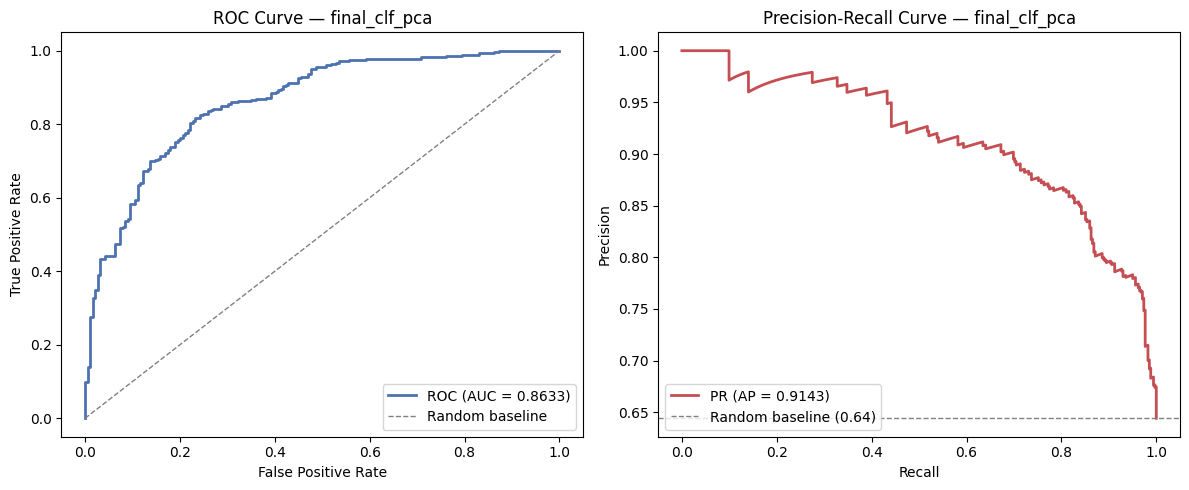

ROC AUC: 0.8633
Average Precision: 0.9143


In [ ]:
#ROC CURVE
import pandas as pd
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import joblib

feature_cols = ['date_numeric', 'encoded_social_class'] + [f'pca_{i}' for i in range(50)]

#held-out test set
test = pd.read_csv('/content/mydrive/MyDrive/pca_held_out_test.csv')
X_test, y_test = test[feature_cols], test['target']

final_clf_pca = joblib.load('/content/mydrive/MyDrive/final_clf_pca.joblib')

# Predicted probability of execution for each held-out row.
# The curves use these raw probabilities, so they don't depend on any cutoff.
probs = final_clf_pca.predict_proba(X_test)[:, 1]

# ROC curve: true positive rate against false-positive rate across every possible cutoff
fpr, tpr, _ = roc_curve(y_test, probs)
roc_auc = auc(fpr, tpr)

# Precision-Recall curve
# Precision against recall across every cutoff, for the executed class
precision, recall, _ = precision_recall_curve(y_test, probs)
avg_precision = average_precision_score(y_test, probs)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, color='#4C72B0', linewidth=2, label=f'ROC (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Random baseline')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — final_clf_pca')
axes[0].legend(loc='lower right')
#The PR baseline is the share of executions in the test set (about 0.64)
baseline_precision = y_test.mean()
axes[1].plot(recall, precision, color='#C44E52', linewidth=2, label=f'PR (AP = {avg_precision:.4f})')
axes[1].axhline(baseline_precision, color='gray', linestyle='--', linewidth=1, label=f'Random baseline ({baseline_precision:.2f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve — final_clf_pca')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.savefig('/content/mydrive/MyDrive/roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"ROC AUC: {roc_auc:.4f}")
print(f"Average Precision: {avg_precision:.4f}")

In [ ]:
# 30-split variance experiment with PCA model. How much does the test AUC change with the random split?
# Uses the tuned hyperparameters from the saved optuna study (loaded below)
import numpy as np
import pandas as pd
import xgboost as xgb
import optuna
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

DRIVE = '/content/mydrive/MyDrive'
study = optuna.load_study(study_name='xgb_pca_wallon_tuning_v1', storage=f'sqlite:///{DRIVE}/optuna_pca.db')

df = pd.read_csv('/content/mydrive/MyDrive/wallon_archives.csv')
df_filtered_data = df.drop_duplicates(subset='cluster_id', keep='first')
print(f"Original rows: {len(df)}")
print(f"Using deduplicated rows:{len(df_filtered_data)}")

feature_cols = ['date_numeric', 'encoded_social_class'] + [f'pca_{i}' for i in range(50)]

pca_aucs = []
for rs in range(30):
    # A different random 60/20/20 train/validation/test split for each seed
    train_val, test = train_test_split(df_filtered_data, test_size=0.2, random_state=rs)
    train, val = train_test_split(train_val, test_size=0.25, random_state=rs)

    X_train, y_train = train[feature_cols], train['target']
    X_val, y_val = val[feature_cols], val['target']
    X_test, y_test = test[feature_cols], test['target']

    spw = (y_train == 0).sum() / (y_train == 1).sum() # class balance: acquittals / executions

   # Tuned hyperparameters stay fixed. Only the split changes.
    xgb_params = dict(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=300,
    scale_pos_weight=spw,
    random_state=42,
    early_stopping_rounds=15,
    n_jobs=-1,
    **study.best_params,
)


    clf = xgb.XGBClassifier(**xgb_params)
    clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    preds_test = clf.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, preds_test)
    pca_aucs.append(auc)
    print(f"rs={rs}: stopped at tree {clf.best_iteration}, AUC={auc:.4f}")
# Spread of test AUC across the 30 splits.
pca_aucs = np.array(pca_aucs)
print(f"\n[PCA] mean={pca_aucs.mean():.4f} std={pca_aucs.std():.4f} "
      f"min={pca_aucs.min():.4f} max={pca_aucs.max():.4f} range={pca_aucs.max()-pca_aucs.min():.4f}")

In [ ]:

# CamemBERT — Step 1: Optuna search (with held-out test set carved off first)
# Do NOT rerun: overwrites cam_held_out_test.csv, cam_train_val.csv and final_clf_cam.joblib
# Needs a GPU runtime (device="cuda")

import optuna
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
import numpy as np
import xgboost as xgb
import pandas as pd
from sklearn.metrics import roc_auc_score, classification_report
import joblib
DRIVE = '/content/mydrive/MyDrive'

# One row per cluster_id, near-duplicate charges would otherwise inflate AUC
df_cam = pd.read_csv(f'{DRIVE}/wallon_cleaned_charges_v5.csv')
df_cam = df_cam.drop_duplicates(subset='cluster_id', keep='first').reset_index(drop=True)
feature_cols_cam = ['date_numeric', 'encoded_social_class'] + [f'cam_emb_{i}' for i in range(1024)]

# Carve off the 20% held-out test set before any tuning. Splitting by cluster_id
# keeps every charge from one cluster on the same side. This is an additional safeguard(the deduplication above already leaves one row per cluster)
# so no near duplicate crosses the split.
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_val_idx, test_idx = next(gss.split(df_cam, groups=df_cam['cluster_id']))

train_val_cam = df_cam.iloc[train_val_idx].reset_index(drop=True)
test_cam = df_cam.iloc[test_idx].reset_index(drop=True)

print(f"train_val rows: {len(train_val_cam)}, test rows: {len(test_cam)}")

# Save the held-out test set so every later step reuses the same untouched 20%
test_cam.to_csv('/content/mydrive/MyDrive/cam_held_out_test.csv', index=False)
train_val_cam.to_csv('/content/mydrive/MyDrive/cam_train_val.csv', index=False)

# Optuna now only ever sees train_val
X_all_cam = train_val_cam[feature_cols_cam]
y_all_cam = train_val_cam['target']
groups_cam = train_val_cam['cluster_id']

def objective_cam(trial):
    # Each trial proposes one set of xgboost settings within these ranges.
    # n_estimators is not searched, early stopping picks the tree count in each fold.
    params = {
      'max_depth': trial.suggest_int('max_depth', 3, 8),
      'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
      'gamma': trial.suggest_float('gamma', 0.0, 0.5),
      'subsample': trial.suggest_float('subsample', 0.6, 1.0),
      'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
      'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
      'reg_lambda': trial.suggest_float('reg_lambda', 0.5, 3.0),
      'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
    }
    # 5-fold cross-validation, grouped by cluster_id so duplicates never sit in both
    # train and validation.
    gkf = GroupKFold(n_splits=5)
    fold_aucs = []
    fold_best_iters = []

    for train_idx, val_idx in gkf.split(X_all_cam, y_all_cam, groups=groups_cam):
        X_tr, X_va = X_all_cam.iloc[train_idx], X_all_cam.iloc[val_idx]
        y_tr, y_va = y_all_cam.iloc[train_idx], y_all_cam.iloc[val_idx]
        # Class balance: acquittals/executions
        spw = (y_tr == 0).sum() / (y_tr == 1).sum()

        clf = xgb.XGBClassifier(
            objective="binary:logistic",
            eval_metric="auc",
            n_estimators=300,
            scale_pos_weight=spw,
            random_state=42,
            n_jobs=-1,
            device = "cuda", # needs gpu runtime
            early_stopping_rounds=15,
            **params
        )

        clf.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        preds = clf.predict_proba(X_va)[:, 1]
        fold_aucs.append(roc_auc_score(y_va, preds))
        fold_best_iters.append(clf.best_iteration)
    # keep average stopping point; final model uses it as tree count
    trial.set_user_attr('mean_best_iteration', float(np.mean(fold_best_iters)))
    return np.mean(fold_aucs)

# The study of all trials is stored in a database file on Drive and reloaded here.
# TPESampler(seed=42) makes the search repeatable
study_cam = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42),
    storage=f'sqlite:///{DRIVE}/optuna_cam.db',
    study_name='xgb_cam_wallon_v1',
    load_if_exists=True,
)
# Runs only trials still missing from 50; once 50 exist, n_trials is 0 and nothing is searched.
study_cam.optimize(objective_cam, n_trials=max(0,50 - len(study_cam.trials)), timeout=3600)
print("Best CV AUC:", study_cam.best_value)
print("Best params:", study_cam.best_params)
print("Mean best iteration:", study_cam.best_trial.user_attrs['mean_best_iteration'])



# CamemBERT — Step 2: final_clf trained on train_val, evaluated once on held-out test

train_val_cam = pd.read_csv('/content/mydrive/MyDrive/cam_train_val.csv')
test_cam = pd.read_csv('/content/mydrive/MyDrive/cam_held_out_test.csv')

X_train_val_cam, y_train_val_cam = train_val_cam[feature_cols_cam], train_val_cam['target']
X_test_cam, y_test_cam = test_cam[feature_cols_cam], test_cam['target']

spw_cam = (y_train_val_cam == 0).sum() / (y_train_val_cam == 1).sum()

best_params_cam = study_cam.best_params
# No validation fold here to stop on, so use the average stopping point from the search.
n_estimators_final_cam = round(study_cam.best_trial.user_attrs['mean_best_iteration'])

final_clf_cam = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=n_estimators_final_cam,
    scale_pos_weight=spw_cam,
    random_state=42,
    n_jobs=-1,
    device="cuda",
    **best_params_cam
)

final_clf_cam.fit(X_train_val_cam, y_train_val_cam)
# Score the held-out test once; 0.50 is the cutoff for outcome.
preds_test_cam = final_clf_cam.predict_proba(X_test_cam)[:, 1]
preds_test_binary_cam = (preds_test_cam >= 0.50).astype(int)

auc_cam = roc_auc_score(y_test_cam, preds_test_cam)
print(f"[CamemBERT] n_estimators used: {n_estimators_final_cam}")
print(f"[CamemBERT] ROC_TEST_SCORE: {auc_cam:.4f}\n")

report_cam = classification_report(y_test_cam, preds_test_binary_cam, target_names=['Acquitted', 'Executed'], output_dict=True)
print(f"[CamemBERT] Executed_recall:{report_cam['Executed']['recall']:.3f}")
print(f"[CamemBERT] Executed_precision:{report_cam['Executed']['precision']:.3f}")
print(f"[CamemBERT] Acquitted_recall:{report_cam['Acquitted']['recall']:.3f}")
print(f"[CamemBERT] Acquitted_precision:{report_cam['Acquitted']['precision']:.3f}")

joblib.dump(final_clf_cam, f'{DRIVE}/final_clf_cam.joblib')

In [ ]:
#XGBOOST MODEL with cam — 30-split variance experiment

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
DRIVE = '/content/mydrive/MyDrive'
import optuna

# Load the tuned hyperparameters from the saved optuna study for camembert
study_cam = optuna.load_study(study_name='xgb_cam_wallon_v1',
                              storage=f'sqlite:///{DRIVE}/optuna_cam.db')

# Same deduplicated data as the main experiments. One row per cluster.
df_cam = pd.read_csv(f'{DRIVE}/wallon_cleaned_charges_v5.csv')
df_cam_filtered = df_cam.drop_duplicates(subset='cluster_id', keep='first')
print(f"Original rows: {len(df_cam)}")
print(f"Using deduplicated rows:{len(df_cam_filtered)}")

feature_cols_cam = ['date_numeric', 'encoded_social_class'] + [f'cam_emb_{i}' for i in range(1024)]

cam_aucs = []
for rs in range(30):
    # A different random 60/20/20 train / validation / test split for each seed.
    train_val, test = train_test_split(df_cam_filtered, test_size=0.2, random_state=rs)
    train, val = train_test_split(train_val, test_size=0.25, random_state=rs)

    X_train, y_train = train[feature_cols_cam], train['target']
    X_val, y_val = val[feature_cols_cam], val['target']
    X_test, y_test = test[feature_cols_cam], test['target']

    spw = (y_train == 0).sum() / (y_train == 1).sum()

    # Tuned hyperparameters stay fixed, only the split changes
    # The validation set is used for early stopping.
    xgb_params = dict(
        objective="binary:logistic",
        eval_metric="auc",
        n_estimators=300,
        scale_pos_weight=spw,
        random_state=42,
        early_stopping_rounds=15,
        n_jobs=-1,
        device = "cuda",   # needs gpu runtime
        **study_cam.best_params,
    )

    clf = xgb.XGBClassifier(**xgb_params)
    clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    preds_test = clf.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, preds_test)
    cam_aucs.append(auc)
    print(f"rs={rs}: stopped at tree {clf.best_iteration}, AUC={auc:.4f}")

# Spread of test AUC across the 30 splits
cam_aucs = np.array(cam_aucs)
print(f"\n[CamemBERT] mean={cam_aucs.mean():.4f} std={cam_aucs.std():.4f} "
      f"min={cam_aucs.min():.4f} max={cam_aucs.max():.4f} range={cam_aucs.max()-cam_aucs.min():.4f}")

In [ ]:
# Deduplication Impact: the same fixed setting scored on deduplicated vs non-deduplicated data.
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import optuna
DRIVE = '/content/mydrive/MyDrive'

# Tuned hyperparameters from the saved optuna studies (pca vs camembert)
study = optuna.load_study(
    study_name='xgb_pca_wallon_tuning_v1',
    storage=f'sqlite:///{DRIVE}/optuna_pca.db',
)
study_cam = optuna.load_study(
    study_name='xgb_cam_wallon_v1',
    storage=f'sqlite:///{DRIVE}/optuna_cam.db',
)

#print(study.best_value, study.best_trial.user_attrs['mean_best_iteration'])
#print(study_cam.best_value, study_cam.best_trial.user_attrs['mean_best_iteration'])

#  Load both datasets: raw = all rows, dedup = one row per cluster_id(near duplicate charges are removed)
df_pca_raw = pd.read_csv('/content/mydrive/MyDrive/wallon_archives.csv')
df_pca_dedup = df_pca_raw.drop_duplicates(subset='cluster_id', keep='first').reset_index(drop=True)

df_cam_raw = pd.read_csv('/content/mydrive/MyDrive/wallon_cleaned_charges_v5.csv')
df_cam_dedup = df_cam_raw.drop_duplicates(subset='cluster_id', keep='first').reset_index(drop=True)

print(f"PCA — raw: {len(df_pca_raw)}, dedup: {len(df_pca_dedup)}")
print(f"CamemBERT — raw: {len(df_cam_raw)}, dedup: {len(df_cam_dedup)}")

best_params_pca = study.best_params
best_params_cam = study_cam.best_params

# The three ways of encoding who the defendant was, each tested with each embedding.
class_configs = {
    'occupation': ['encoded_occupation'],
    'social_class': ['encoded_social_class'],
    'social_class + occupation': ['encoded_social_class', 'encoded_occupation'],
}

def run_combo(df, embed_cols, class_cols, best_params, seed=42):
    feature_cols = ['date_numeric'] + class_cols + embed_cols
    # Plain random 60/20/20 split, deliberately not grouped by cluster_id
    train_val, test = train_test_split(df, test_size=0.2, random_state=seed)
    train, val = train_test_split(train_val, test_size=0.25, random_state=seed)

    X_train, y_train = train[feature_cols], train['target']
    X_val, y_val = val[feature_cols], val['target']
    X_test, y_test = test[feature_cols], test['target']

    spw = (y_train == 0).sum() / (y_train == 1).sum() # class balance: acquittals/executed

    # Same fixed settings for every combination; the validation set is used only for early stopping
    clf = xgb.XGBClassifier(
        objective="binary:logistic", eval_metric="auc", n_estimators=300,
        scale_pos_weight=spw, random_state=42, n_jobs=-1,
        early_stopping_rounds=15, **best_params
    )
    clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    preds = clf.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, preds)

pca_embed_cols = [f'pca_{i}' for i in range(50)]
cam_embed_cols = [f'cam_emb_{i}' for i in range(1024)]

# Six feature sets (2 embeddings * 3 class encodings), each scored on dedup and on raw data
results = []
for class_name, class_cols in class_configs.items():
    auc_pca_dedup = run_combo(df_pca_dedup, pca_embed_cols, class_cols, best_params_pca)
    auc_pca_raw = run_combo(df_pca_raw, pca_embed_cols, class_cols, best_params_pca)
    results.append(('PCA-50', class_name, auc_pca_dedup, auc_pca_raw))
    print(f"PCA-50 + {class_name}: dedup={auc_pca_dedup:.4f}, raw={auc_pca_raw:.4f}")

    auc_cam_dedup = run_combo(df_cam_dedup, cam_embed_cols, class_cols, best_params_cam)
    auc_cam_raw = run_combo(df_cam_raw, cam_embed_cols, class_cols, best_params_cam)
    results.append(('CamemBERT-1024', class_name, auc_cam_dedup, auc_cam_raw))
    print(f"CamemBERT-1024 + {class_name}: dedup={auc_cam_dedup:.4f}, raw={auc_cam_raw:.4f}")

# gap = raw AUC minus dedup AUC: the inflation caused by near-duplicates.
results_df = pd.DataFrame(results, columns=['embedding', 'class_feature', 'dedup_auc', 'raw_auc'])
results_df['gap'] = results_df['raw_auc'] - results_df['dedup_auc']
print(results_df)

In [ ]:
#ablation using validation slice of train_val, not held-out test: how much does each group of features contribute?
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
import xgboost as xgb
import pandas as pd

train_val = pd.read_csv('/content/mydrive/MyDrive/pca_train_val.csv')

def eval_feature_set(feature_cols, label):
    X, y = train_val[feature_cols], train_val['target']
    # 80/20 split of train_val, stratified so both parts keep the same share of executions.
    X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    spw = (y_tr == 0).sum() / (y_tr == 1).sum() # class balance: acquittals/executed
    # Fixed setting for every feature set so differences in AUC come from the features, not from the model.
    clf = xgb.XGBClassifier(objective="binary:logistic", eval_metric="auc",
                             n_estimators=45, scale_pos_weight=spw, random_state=42, n_jobs=-1)
    clf.fit(X_tr, y_tr)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:, 1])
    print(f"{label}: AUC = {auc:.4f}")
    return auc

pca_cols = [f'pca_{i}' for i in range(50)]
# Three feature sets, how much does text add on top of date and class?
auc_full      = eval_feature_set(['date_numeric', 'encoded_social_class'] + pca_cols, "Full (date+class+PCA)")
auc_tabular   = eval_feature_set(['date_numeric', 'encoded_social_class'],            "Tabular only (date+class)")
auc_pca_only  = eval_feature_set(pca_cols,                                             "PCA only (no date/class)")

Full (date+class+PCA): AUC = 0.8325
Tabular only (date+class): AUC = 0.8144
PCA only (no date/class): AUC = 0.6904


In [ ]:
#ablation using held-out test set: same three features as evaluation cell
from sklearn.metrics import roc_auc_score
import xgboost as xgb
import pandas as pd

train_val = pd.read_csv('/content/mydrive/MyDrive/pca_train_val.csv')
test      = pd.read_csv('/content/mydrive/MyDrive/pca_held_out_test.csv')

def eval_feature_set(feature_cols, label):
    X_tr, y_tr = train_val[feature_cols], train_val['target']
    X_te, y_te = test[feature_cols],      test['target']
    spw = (y_tr == 0).sum() / (y_tr == 1).sum()
    # Fixed setting for every feature set so differences in AUC come from the features, not from the model.
    clf = xgb.XGBClassifier(objective="binary:logistic", eval_metric="auc",
                            n_estimators=45, scale_pos_weight=spw,
                            random_state=42, n_jobs=-1)

    clf.fit(X_tr, y_tr)
    auc = roc_auc_score(y_te, clf.predict_proba(X_te)[:, 1])
    print(f"{label}: AUC = {auc:.4f}")
    return auc

pca_cols = [f'pca_{i}' for i in range(50)]
# Three feature sets, how much does text add on top of date and class?
auc_full     = eval_feature_set(['date_numeric', 'encoded_social_class'] + pca_cols, "Full (date+class+PCA)")
auc_tabular  = eval_feature_set(['date_numeric', 'encoded_social_class'],            "Tabular only (date+class)")
auc_pca_only = eval_feature_set(pca_cols,                                             "PCA only (no date/class)")

Full (date+class+PCA): AUC = 0.8445
Tabular only (date+class): AUC = 0.8100
PCA only (no date/class): AUC = 0.6878


In [ ]:
#pca variance: share of the original 1,024 camembert dimension that the pca-50 components retain.
import joblib
pca = joblib.load('/content/mydrive/MyDrive/fitted_pca.joblib')
print(f"{pca.explained_variance_ratio_.sum():.1%}")

64.2%


In [ ]:
# Gain rank of every feature in the PCA model, on full and deduplicated data
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
!pip install optuna==5.0.0 --quiet
import optuna
DRIVE = '/content/mydrive/MyDrive'

df = pd.read_csv(f'{DRIVE}/wallon_archives.csv')
feature_cols = ['date_numeric', 'encoded_social_class'] + [f'pca_{i}' for i in range(50)]
# Tuned hyperparameters from the saved PCA study.
best = optuna.load_study(study_name='xgb_pca_wallon_tuning_v1', storage=f'sqlite:///{DRIVE}/optuna_pca.db').best_params
# Same settings as the final model
xgb_params = dict(
    objective="binary:logistic", eval_metric="auc",
    n_estimators=45, random_state=42, n_jobs=-1,
    **best,
)

def gain_rank(data, feature_cols, xgb_params):
    """
    Fit on the training rows only and rank features by gain (how much each feature improves the splits it is used in)
    """
    train_val, test = train_test_split(data, test_size=0.2, random_state=42)
    train, val = train_test_split(train_val, test_size=0.25, random_state=42)
    X_train, y_train = train[feature_cols], train['target']

    spw = (y_train == 0).sum() / (y_train == 1).sum() # class balance: acquittal/executed
    params = dict(xgb_params, scale_pos_weight=spw)
    clf = xgb.XGBClassifier(**params)
    clf.fit(X_train, y_train)
    # Features never used in a split are missing from get_score, so ranks cover only the used ones.
    gains = pd.Series(clf.get_booster().get_score(importance_type='gain'), name='gain').sort_values(ascending=False)
    ranks = gains.rank(ascending=False).astype(int)
    return pd.DataFrame({'gain': gains, 'rank': ranks})

# non-deduplicated
rank_full = gain_rank(df, feature_cols, xgb_params)
print("Non-deduplicated:")
print(rank_full.head(15))

# deduplicated
df_filtered = df.drop_duplicates(subset='cluster_id', keep='first')
rank_dedup = gain_rank(df_filtered, feature_cols, xgb_params)
print("\nDeduplicated:")
print(rank_dedup.head(15))


In [ ]:
# Embedding component interpretation: charge text at the extremes of pca_4, pca_0, pca_7 and pca_2
import pandas as pd
DRIVE = '/content/mydrive/MyDrive'
df = pd.read_csv(f'{DRIVE}/wallon_archives.csv')
# PCA Components have no built-in meaning, so read the charge text at both ends of each one
# For each component, sort all rows by value, take 15 lowest and 15 highest
for comp in ['pca_4', 'pca_0','pca_7','pca_2']:
    s = df.sort_values(comp)
    print(f"\n===== {comp}: LOW end =====")
    print(s['cleaned_charge'].head(15).value_counts().head(8))
    print(f"\n===== {comp}: HIGH end =====")
    print(s['cleaned_charge'].tail(15).value_counts().head(8))

In [ ]:
#SHAP Dependence Plot: how social class pushes the model's score up or down
import shap
import pandas as pd

import joblib
DRIVE = '/content/mydrive/MyDrive'
# Final trained model and held-out test rows, so the explanations cover trials the model never trained on
clf = joblib.load(f'{DRIVE}/final_clf_pca.joblib')
test = pd.read_csv(f'{DRIVE}/pca_held_out_test.csv')
X_test = test[['date_numeric', 'encoded_social_class'] + [f'pca_{i}' for i in range(50)]]

#shap value = how much each feature contributed to result, relative to average prediction
explainer = shap.TreeExplainer(clf)
shap_values = explainer(X_test)

# Pick the colour feature automatically. approximate_interactions sorts the rows by
# class, cuts them into chunks, and checks which other feature's raw values move
# together with class's shap values. It returns feature indices strongest first,
# so [0] is the best partner.
interaction_idx = shap.utils.approximate_interactions(
    'encoded_social_class', shap_values.values, X_test
)
top_interacting_feature = X_test.columns[interaction_idx[0]]
print(f"Strongest interacting feature with encoded_social_class: {top_interacting_feature}")

# One dot per test trial: x = class code, y = its shap value, colour = the interacting feature
shap.plots.scatter(
    shap_values[:, "encoded_social_class"],
    color=shap_values[:, top_interacting_feature]
)



Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Actual outcome: executed (1)

Baseline: -0.0320
encoded_social_class    0.550372
pca_6                   0.291414
pca_0                   0.288732
pca_16                  0.282061
date_numeric           -0.249692
pca_1                   0.221450
pca_2                   0.202531
pca_41                  0.194915
pca_15                  0.098095
pca_4                   0.087545
pca_7                  -0.081926
pca_14                 -0.069490
pca_30                  0.061658
pca_12                  0.059750
pca_44                  0.052836
pca_29                  0.050781
pca_39                 -0.043674
pca_49                  0.042199
pca_24                 -0.038264
pca_19                  0.031728
pca_9                  -0.029845
pca_11                  0.029592
pca_22                  0.027858
pca_34                 -0.027290
pca_3                  -0.027103
pca_40                 -0.026562
pca_25                  0.026103
pca_8                   0.025373
pca_42                  0.02

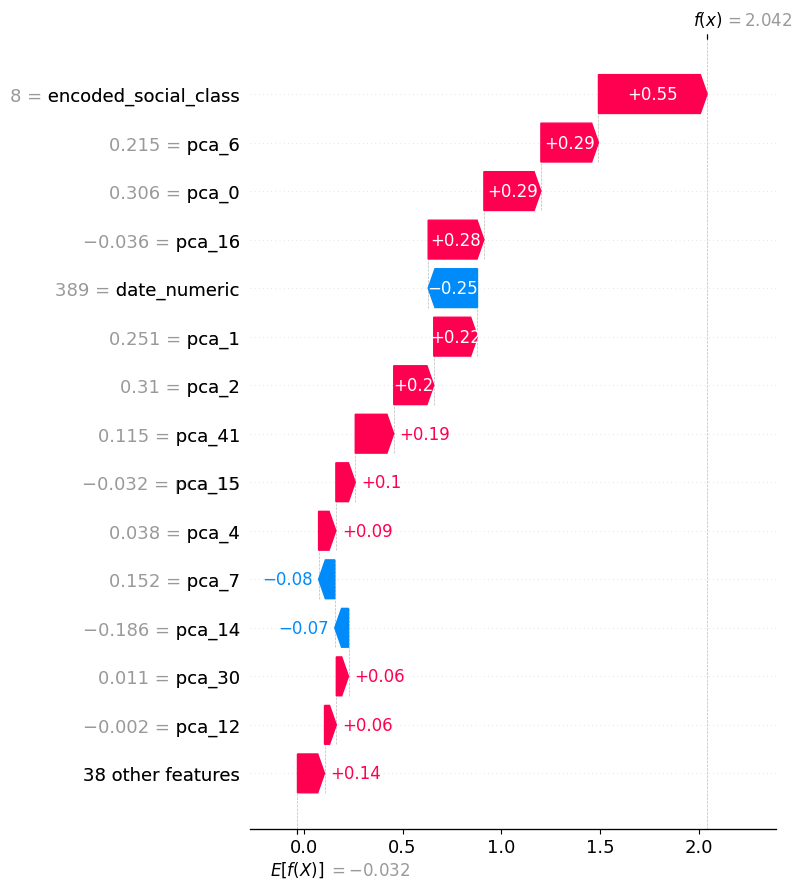

In [5]:
# Shap Waterfall: Marie-Antoinette (held out of training)
# Shows how each feature pushed the model's score up or down for one trial
import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

DRIVE = '/content/mydrive/MyDrive'
feature_cols = ['date_numeric', 'encoded_social_class'] + [f'pca_{i}' for i in range(50)]

final_clf_pca = joblib.load(f'{DRIVE}/final_clf_pca.joblib')
pca = joblib.load(f'{DRIVE}/fitted_pca.joblib')

# the three inputs for this case
charge_text = "conspiration contre l'unité et l'indivisibilité de la République / conspiration contre la liberté et la sûreté du peuple français / dilapidations / intelligences avec les nations étrangères / excitation à la guerre civile"
date_numeric = 389      # 16 octobre 1793
social_class = 8      # nobility

# Embed charge_text (normalized, like the stored embeddings), then project to 50 PCA components
embedder = SentenceTransformer('dangvantuan/sentence-camembert-large')
emb = pca.transform(embedder.encode([charge_text], normalize_embeddings=True))

# One row table in the exact column order the model was trained on
row = pd.DataFrame(emb, columns=[f'pca_{i}' for i in range(50)])
row.insert(0, 'encoded_social_class', social_class)
row.insert(0, 'date_numeric', date_numeric)
row = row[feature_cols]
print("Actual outcome: executed (1)")

# shap splits this one prediction into a baseline plus one contribution per feature.
# All values are in log-odds, the model's raw output before conversion to a probability
explainer = shap.TreeExplainer(final_clf_pca)
shap_values = explainer(row)

baseline = explainer.expected_value
contribs = pd.Series(shap_values.values[0], index=feature_cols).sort_values(key=abs, ascending=False)
total_margin = baseline + contribs.sum()
prob = 1 / (1 + np.exp(-total_margin))  # sigmoid: log-odds to a 0-1 score

# Sanity check: baseline plus contribs should equal model's raw output
print(f"\nBaseline: {baseline:.4f}")
print(contribs)
print(f"\nSum check: {total_margin:.4f}")
print(f"Model's raw margin: {final_clf_pca.predict(row, output_margin=True)[0]:.4f}")
print(f"Predicted execution probability: {prob*100:.1f}%")

shap.plots.waterfall(shap_values[0], max_display=15, show=False)
plt.tight_layout()
plt.savefig(f'{DRIVE}/waterfall_marie.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Charge clustering: HDBSCAN on the PCA-50 text components, UMAP for the 2d picture
import pandas as pd
import numpy as np
!pip install hdbscan==0.8.44 umap-learn==0.5.12 --quiet
import hdbscan
import umap

# use all (non-deduplicated) rows, so formulaic charges or co-defendants can form clusters
df = pd.read_csv('/content/mydrive/MyDrive/wallon_archives.csv')
pca_cols = [f'pca_{i}' for i in range(50)]
X = df[pca_cols].values

# HDBSCAN clustering
# groups charges that sit close together in the 50-dimension text space
# cluster needs at least 5 charges; label -1 means belongs to no cluster
clusterer = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=5, metric='euclidean')
df['hdbscan_label'] = clusterer.fit_predict(X)

n_clusters = df['hdbscan_label'].nunique() - (1 if -1 in df['hdbscan_label'].unique() else 0)
n_noise = (df['hdbscan_label'] == -1).sum()
print(f"HDBSCAN found {n_clusters} clusters, {n_noise} unclustered (noise) points out of {len(df)}")

# size and outcome rate per cluster
# cluster qualifies with at least 10 trials and an execution rate of 85% or more or 15% or less(acquittal-associated)
cluster_stats = (
    df[df['hdbscan_label'] != -1]
    .groupby('hdbscan_label')
    .agg(n=('target', 'size'), exec_rate=('target', 'mean'))
    .reset_index()
)
strong_clusters = cluster_stats[
    (cluster_stats['n'] >= 10) & ((cluster_stats['exec_rate'] >= 0.85) | (cluster_stats['exec_rate'] <= 0.15))
].sort_values('n', ascending=False)

print(f"\n{len(strong_clusters)} clusters meet the n>=10, >=85% or <=15% execution-rate threshold")
print(strong_clusters)

# Inspect top charge text for the largest qualifying clusters
print("\n=== Top execution-associated clusters (>=85%), largest first ===")
exec_clusters = strong_clusters[strong_clusters['exec_rate'] >= 0.85].sort_values('n', ascending=False)
for _, row in exec_clusters.head(8).iterrows():
    label = row['hdbscan_label']
    sub = df[df['hdbscan_label'] == label]
    print(f"\n--- Cluster {label} (n={row['n']}, exec_rate={row['exec_rate']:.2f}) ---")
    print(sub['cleaned_charge'].value_counts().head(5))

print("\n=== Top acquittal-associated clusters (<=15%), largest first ===")
acq_clusters = strong_clusters[strong_clusters['exec_rate'] <= 0.15].sort_values('n', ascending=False)
for _, row in acq_clusters.head(8).iterrows():
    label = row['hdbscan_label']
    sub = df[df['hdbscan_label'] == label]
    print(f"\n--- Cluster {label} (n={row['n']}, exec_rate={row['exec_rate']:.2f}) ---")
    print(sub['cleaned_charge'].value_counts().head(5))

# UMAP for visualization
# squeezes 50 dimensions to 2 so the charges can be plotted.
reducer = umap.UMAP(n_components=2, random_state=42)
embedding_2d = reducer.fit_transform(X)
df['umap_x'] = embedding_2d[:, 0]
df['umap_y'] = embedding_2d[:, 1]

# Check case: charges mentioning the Baron de Batz plot. Which clusters do they land in and are they lopsided toward executions?
# Baron de Batz plots refers to series of attempts to rescue nobility
b = df[df['cleaned_charge'].str.contains('Batz', case=False, na=False)]
print(len(b))
print(b.groupby('hdbscan_label').agg(n=('target','size'), exec_rate=('target','mean')))
print(b['cleaned_charge'].value_counts().head(5))

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(df['umap_x'], df['umap_y'], c=df['target'], cmap='coolwarm', s=5, alpha=0.6)
plt.colorbar(label='target (0=acquitted, 1=executed)')
plt.title('UMAP projection of PCA-50 charge embeddings, colored by outcome')
plt.savefig('/content/mydrive/MyDrive/umap_outcome.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Full list of qualifying clusters, with the 3 most common charge wordings in each
# Needs df and strong_clusters from the clustering cell above, so run that one first

# Execution-associated clusters, largest first
print("=== ALL execution-associated clusters (>=85%) ===")
exec_clusters_all = strong_clusters[strong_clusters['exec_rate'] >= 0.85].sort_values('n', ascending=False)
for _, row in exec_clusters_all.iterrows():
    label = row['hdbscan_label']
    sub = df[df['hdbscan_label'] == label]
    print(f"\n--- Cluster {label} (n={row['n']}, exec_rate={row['exec_rate']:.2f}) ---")
    print(sub['cleaned_charge'].value_counts().head(3))
# Acquittal-associated clusters, largest first
print("\n\n=== ALL acquittal-associated clusters (<=15%) ===")
acq_clusters_all = strong_clusters[strong_clusters['exec_rate'] <= 0.15].sort_values('n', ascending=False)
for _, row in acq_clusters_all.iterrows():
    label = row['hdbscan_label']
    sub = df[df['hdbscan_label'] == label]
    print(f"\n--- Cluster {label} (n={row['n']}, exec_rate={row['exec_rate']:.2f}) ---")
    print(sub['cleaned_charge'].value_counts().head(3))


In [ ]:
# ---------------- Single grouped bar graph: acquittal and execution side by side ----------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DRIVE = '/content/mydrive/MyDrive'
df = pd.read_csv(f'{DRIVE}/wallon_archives.csv', low_memory=False)


prairial_dn  = 626    # 10 June 1794 (Law of 22 Prairial)
thermidor_dn = 673    # 27 July 1794 (Thermidorian Reaction)

# 30 equal width time bins across the whole date range.
bins = np.linspace(df['date_numeric'].min(), df['date_numeric'].max(), 31)
bin_width_full = bins[1] - bins[0]
bar_width = bin_width_full * 0.42  # each bar takes ~42% of the bin, leaving a gap between groups

acquitted = df[df['target'] == 0]
executed = df[df['target'] == 1]

# Count trials of each outcome in each bin; the bin centers place the bars on the x-axis
acq_counts, _ = np.histogram(acquitted['date_numeric'], bins=bins)
exec_counts, _ = np.histogram(executed['date_numeric'], bins=bins)
bin_centers = (bins[:-1] + bins[1:]) / 2

fig, ax = plt.subplots(figsize=(13, 6))

# Shift the two bars left and right of each bin's center so they sit side by side
ax.bar(bin_centers - bar_width/2, acq_counts, width=bar_width, color='#4C72B0', alpha=0.85, label='Acquitted')
ax.bar(bin_centers + bar_width/2, exec_counts, width=bar_width, color='#C44E52', alpha=0.85, label='Executed')

# Dashed lines at the two events that bound the peak of the executions.
ax.axvline(prairial_dn, color='blue', linestyle='--', linewidth=1.5, label='Law of 22 Prairial (10 June 1794)')
ax.axvline(thermidor_dn, color='red', linestyle='--', linewidth=1.5, label='Thermidorian Reaction (27 July 1794)')

ax.set_xlabel('date_numeric')
ax.set_ylabel('Count')
ax.set_title('Acquittals vs. executions over time')
ax.legend()

plt.tight_layout()
plt.savefig('/content/mydrive/MyDrive/date_numeric_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Showcase rescoring with the final model
import pandas as pd, joblib, json
from datetime import date
from sentence_transformers import SentenceTransformer

# Rescore the showcase people's extracted charges with the final model, then add Dubarry
# Each person's score in the writeup is the mean of the per-charge scores
DRIVE = '/content/mydrive/MyDrive'
RESULTS = f'{DRIVE}/results'
START = date(1792, 9, 22)

pca = joblib.load(f'{DRIVE}/fitted_pca.joblib')
clf = joblib.load(f'{DRIVE}/final_clf_pca.joblib')
cam = SentenceTransformer("dangvantuan/sentence-camembert-large")
feature_cols = ['date_numeric', 'encoded_social_class'] + [f'pca_{i}' for i in range(50)]

def to_days(d):
    y, m, dd = map(int, d.split('-'))
    return (date(y, m, dd) - START).days

def score(texts, dates, classes):
    emb = cam.encode(texts, batch_size=32, normalize_embeddings=True)
    X = pd.DataFrame(pca.transform(emb), columns=[f'pca_{i}' for i in range(50)])
    X['date_numeric'] = dates
    X['encoded_social_class'] = classes
    return clf.predict_proba(X[feature_cols])[:, 1]

for slug in ['houchard', 'danton', 'kellerman', 'robespierre']:
    # One json line per extracted charge: text, date, social class and the earlier score
    rows = [json.loads(l) for l in open(f'{RESULTS}/{slug}_charges.jsonl', encoding='utf-8') if l.strip()]
    texts = [r['cleaned_charge'] for r in rows]
    days = [to_days(r['date']) for r in rows]
    cls = [r['social_class'] for r in rows]
    new = score(texts, days, cls)
    print(f"\n=== {slug} ({len(rows)} charges) ===")
    for r, d, p, t in zip(rows, days, new, texts):
        r['p_execution_new'] = round(float(p), 4)
        # Negative days fall before 22 Sept 1792, where the training data has almost no trials.
        flag = '  before model range' if d < 0 else ''
        # old = score saved earlier by a previous model; new = final model
        print(f"{r['date']} d={d:4d}  old={r['p_execution']:.3f}  new={p:.3f}  {t[:60]}{flag}")
    # save a copy with the new score added; the original file is left untouched.
    with open(f'{RESULTS}/{slug}_rescored.jsonl', 'w', encoding='utf-8') as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')

# Du Barry: use her saved row from earlier, instead of a charge file
db = pd.read_csv(f'{DRIVE}/dubarry_row_saved.csv')
db = db[db['Name'].str.contains('DU BARRY', case=False, na=False)].iloc[0]
p = score([db['cleaned_charge']], [int(db['date_numeric'])], [int(db['encoded_social_class'])])[0]
print(f"\nDu Barry (tribunal charge, date {int(db['date_numeric'])}): p_execution = {p:.3f}")

In [5]:
# Logistic Regression vs xgboost: same inputs as the xgboost model
import pandas as pd, joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

DRIVE = '/content/mydrive/MyDrive'
tv = pd.read_csv(f'{DRIVE}/pca_train_val.csv') # train + validation rows
te = pd.read_csv(f'{DRIVE}/pca_held_out_test.csv') # held out test rows
pcs = [f'pca_{i}' for i in range(50)]

# Logistic regression needs numbers in a form it can use, so prep it differently
prep = ColumnTransformer([
    # Date has a curved effect, executions peak in mid-1794,spline lets a linear model fit that curve.
    ('date', SplineTransformer(n_knots=10, degree=3), ['date_numeric']),
    # put the 50 pca components on one scale so the regularization penalty treats them equally
    ('pca', StandardScaler(), pcs),
    # Class codes are categories, not amount, so each code gets its own 0/1 column
    ('cls', OneHotEncoder(handle_unknown='ignore'), ['encoded_social_class']),
])
cols = ['date_numeric', 'encoded_social_class'] + pcs
# Learn the scalings and categories from the training rows only
Xtv = prep.fit_transform(tv[cols]); Xte = prep.transform(te[cols])

# Five cross-validation splits that never put rows with the same cluster_id on both sides
cv = list(GroupKFold(n_splits=5).split(Xtv, tv['target'], tv['cluster_id']))
# Tries 10 regularization strengths (C) and keeps the one with the best AUC score
# class_weight ='balanced' counts the rarer outcome more, gives minority class more weight during training
# max_iter is raised because the default step limit often stops before the fit settles
lr = LogisticRegressionCV(Cs=10, cv=cv, scoring='roc_auc', max_iter=5000, class_weight='balanced')
lr.fit(Xtv, tv['target'])
auc_lr = roc_auc_score(te['target'], lr.predict_proba(Xte)[:, 1])

xgb_clf = joblib.load(f'{DRIVE}/final_clf_pca.joblib')
auc_xgb = roc_auc_score(te['target'], xgb_clf.predict_proba(te[cols])[:, 1])

print(f"Logistic regression test AUC: {auc_lr:.4f}  (best C = {lr.C_[0]:.3g})")
print(f"XGBoost test AUC:             {auc_xgb:.4f}")


Logistic regression test AUC: 0.8447  (best C = 167)
XGBoost test AUC:             0.8633


In [4]:
# Forward in time check: train only on trials before the law of 22 prairial, test on trials from it onward
import pandas as pd
!pip install optuna==5.0.0 --quiet
import optuna
import xgboost as xgb
from sklearn.metrics import roc_auc_score

DRIVE = '/content/mydrive/MyDrive'
# one row per cluster_id as in the headline model's data.
df = pd.read_csv(f'{DRIVE}/wallon_archives.csv').drop_duplicates(subset='cluster_id', keep='first')
pcs = [f'pca_{i}' for i in range(50)]
# reuse the headline model's tuned settings and tree count
study = optuna.load_study(study_name='xgb_pca_wallon_tuning_v1', storage=f'sqlite:///{DRIVE}/optuna_pca.db')
params = study.best_params
n_trees = round(study.best_trial.user_attrs['mean_best_iteration'])

CUT = 626 # cutoff point
train, test = df[df['date_numeric'] < CUT], df[df['date_numeric'] >= CUT]
print(f"train (before {CUT}): {len(train)} rows, {train['target'].mean():.0%} executed")
print(f"test  (from {CUT}):   {len(test)} rows, {test['target'].mean():.0%} executed")

def fit_eval(cols):
    spw = (train['target'] == 0).sum() / (train['target'] == 1).sum()
    clf = xgb.XGBClassifier(objective='binary:logistic', eval_metric='auc', n_estimators=n_trees,
                            scale_pos_weight=spw, random_state=42, n_jobs=-1, **params)
    clf.fit(train[cols], train['target'])
    return roc_auc_score(test['target'], clf.predict_proba(test[cols])[:, 1])
# Which inputs still help when the period is new?
variants = {
    'Full (date + class + text)':      ['date_numeric', 'encoded_social_class'] + pcs,
    'Date + class only':               ['date_numeric', 'encoded_social_class'],
    'Text + class only (no date)':     ['encoded_social_class'] + pcs,
    'Date only':                       ['date_numeric'],
    'Class only':                      ['encoded_social_class'],
    'Text only':                       pcs,
}
for name, cols in variants.items():
    print(f"{name}: AUC = {fit_eval(cols):.4f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 13.3 MB/s eta 0:00:00
train (before 626): 1273 rows, 62% executed
test  (from 626):   1382 rows, 63% executed
Full (date + class + text): AUC = 0.6624
Date + class only: AUC = 0.6161
Text + class only (no date): AUC = 0.6578
Date only: AUC = 0.5000
Class only: AUC = 0.6267
Text only: AUC = 0.6427


In [ ]:
# Calibration check: when the model says 70%, do about 70% of those trials end in execution?
# Compares the saved model with two recalibrated versions (sigmoid/Platt and isotonic)
import numpy as np, pandas as pd, joblib, xgboost as xgb, optuna
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import GroupKFold
from sklearn.metrics import brier_score_loss

DRIVE = '/content/mydrive/MyDrive'
tv = pd.read_csv(f'{DRIVE}/pca_train_val.csv')
te = pd.read_csv(f'{DRIVE}/pca_held_out_test.csv')
pcs = [f'pca_{i}' for i in range(50)]
cols = ['date_numeric', 'encoded_social_class'] + pcs
# Same tuned settings and tree count as the final model
study = optuna.load_study(study_name='xgb_pca_wallon_tuning_v1', storage=f'sqlite:///{DRIVE}/optuna_pca.db')
params = study.best_params
n_trees = round(study.best_trial.user_attrs['mean_best_iteration'])
# class reweighting shifts the raw probabilities away from true frequencies, which is why calibration is worth checking
spw = (tv['target'] == 0).sum() / (tv['target'] == 1).sum()

def make():
    return xgb.XGBClassifier(objective='binary:logistic', n_estimators=n_trees,
                             scale_pos_weight=spw, random_state=42, n_jobs=-1, **params)

# Group-aware splits, so calibration is learned on rows the model did not train on
cv = list(GroupKFold(n_splits=5).split(tv[cols], tv['target'], tv['cluster_id']))

probs = {'Raw model': joblib.load(f'{DRIVE}/final_clf_pca.joblib').predict_proba(te[cols])[:, 1]}
# Each calibrated version trains a fresh model on 4 of the 5 splits and learns the probability
# correction on the 5th. Its predictions average those 5 models, so it differs from the raw model by more than the correction
for method in ['sigmoid', 'isotonic']:
    cal = CalibratedClassifierCV(make(), method=method, cv=cv)
    cal.fit(tv[cols], tv['target'])
    probs[method] = cal.predict_proba(te[cols])[:, 1]

print(f"Actual execution rate in test: {te['target'].mean():.3f}")
plt.figure(figsize=(6, 6))
for name, p in probs.items():
    # Brier score = average squared gap between predicted probability and the real 0/1 outcome (lower is better)
    print(f"{name}: Brier = {brier_score_loss(te['target'], p):.4f}, mean predicted = {p.mean():.3f}")
    # 8 equal-sized groups of test trials, sorted by predicted probability; plot prediction vs actual rate in each
    frac, mean_p = calibration_curve(te['target'], p, n_bins=8, strategy='quantile')
    plt.plot(mean_p, frac, marker='o', label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Perfect') # a perfectly calibrated model follows this line
plt.xlabel('Predicted probability'); plt.ylabel('Actual fraction executed')
plt.title('Reliability curve (held-out test)'); plt.legend(); plt.show()

In [ ]:
import importlib.metadata as md

packages = ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'optuna', 'joblib',
            'sentence-transformers', 'transformers', 'torch', 'shap',
            'umap-learn', 'hdbscan', 'matplotlib']

for p in packages:
    try:
        print(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        print(f"# {p} not installed")

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1
optuna==5.0.0
joblib==1.6.0
sentence-transformers==5.7.0
transformers==5.18.0
torch==2.11.0+cpu
shap==0.52.0
umap-learn==0.5.12
hdbscan==0.8.44
matplotlib==3.10.0
# google-generativeai not installed


In [ ]:

# Logistic regression on TF-IDF of the cleaned charges, scored on the same held-out test set
# Two variants: (A) charge text only, (B) charge text + date + social class
# Compare with camembert based results in the writeup, camembert vs tf-idf
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, SplineTransformer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

DRIVE = '/content/mydrive/MyDrive'
TEXT_COL = 'cleaned_charge'   # name of the column holding the cleaned French charge text

# Same saved split as every other model, so the test AUCs are directly comparable.
tv = pd.read_csv(f'{DRIVE}/pca_train_val.csv')
te = pd.read_csv(f'{DRIVE}/pca_held_out_test.csv')

# If the split files do not carry the charge text, attach it from the v5 file by Index.
if TEXT_COL not in tv.columns:
    v5 = pd.read_csv(f'{DRIVE}/wallon_cleaned_charges_v5.csv', low_memory=False, usecols=['Index', TEXT_COL])
    tv = tv.merge(v5, on='Index', how='left', validate='one_to_one')
    te = te.merge(v5, on='Index', how='left', validate='one_to_one')

tv[TEXT_COL] = tv[TEXT_COL].fillna('')
te[TEXT_COL] = te[TEXT_COL].fillna('')

# TF-IDF: each charge becomes word and word-pair weights; rare, distinctive words count more.
# min_df=2 drops words seen in only one charge; sublinear_tf dampens very repeated words.
def tfidf():
    return TfidfVectorizer(lowercase=True, strip_accents='unicode', ngram_range=(1, 2),
                           min_df=2, sublinear_tf=True)

# Same cross-validation as the earlier logistic regression: 5 folds, grouped by cluster_id.
cv = list(GroupKFold(n_splits=5).split(tv, tv['target'], tv['cluster_id']))

def fit_and_score(prep, name):
    X_tv = prep.fit_transform(tv)   # vocabulary and IDF learned from train_val only
    X_te = prep.transform(te)
    lr = LogisticRegressionCV(Cs=10, cv=cv, scoring='roc_auc', max_iter=5000, class_weight='balanced')
    lr.fit(X_tv, tv['target'])
    auc = roc_auc_score(te['target'], lr.predict_proba(X_te)[:, 1])
    print(f"{name}: test AUC {auc:.4f}  (best C = {lr.C_[0]:.3g}, {X_tv.shape[1]} features)")
    return auc

# (A) Charge text only.
prep_text = ColumnTransformer([('text', tfidf(), TEXT_COL)])
fit_and_score(prep_text, 'TF-IDF text only')

# (B) Charge text + date (spline) + social class (one-hot), the same non-text inputs as the earlier models.
prep_full = ColumnTransformer([
    ('text', tfidf(), TEXT_COL),
    ('date', SplineTransformer(n_knots=10, degree=3), ['date_numeric']),
    ('cls', OneHotEncoder(handle_unknown='ignore'), ['encoded_social_class']),
])
fit_and_score(prep_full, 'TF-IDF text + date + class')

TF-IDF text only: test AUC 0.7144  (best C = 0.359, 5537 features)
TF-IDF text + date + class: test AUC 0.8543  (best C = 2.78, 5558 features)


np.float64(0.854265292861784)

In [ ]:
# XGBoost on TF-IDF of the cleaned charges, scored on the same held-out test set.
# Two variants: (A) charge text only, (B) charge text + date + social class.
# Compare with other models in write up
# Uses the tuned hyperparameters from the saved PCA Optuna study (loaded below).
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

DRIVE = '/content/mydrive/MyDrive'
study = optuna.load_study(study_name='xgb_pca_wallon_tuning_v1', storage=f'sqlite:///{DRIVE}/optuna_pca.db')
TEXT_COL = 'cleaned_charge'   # name of the column holding the cleaned French charge text

# Same saved split as every other model, so the test AUCs are directly comparable.
tv = pd.read_csv(f'{DRIVE}/pca_train_val.csv')
te = pd.read_csv(f'{DRIVE}/pca_held_out_test.csv')

# If the split files do not carry the charge text, attach it from the v5 file by Index.
if TEXT_COL not in tv.columns:
    v5 = pd.read_csv(f'{DRIVE}/wallon_cleaned_charges_v5.csv', low_memory=False, usecols=['Index', TEXT_COL])
    tv = tv.merge(v5, on='Index', how='left', validate='one_to_one')
    te = te.merge(v5, on='Index', how='left', validate='one_to_one')

tv[TEXT_COL] = tv[TEXT_COL].fillna('')
te[TEXT_COL] = te[TEXT_COL].fillna('')

# TF-IDF: each charge becomes word and word-pair weights; rare, distinctive words count more.
def tfidf():
    return TfidfVectorizer(lowercase=True, strip_accents='unicode', ngram_range=(1, 2),
                           min_df=2, sublinear_tf=True)

y_tv = tv['target'].values
y_te = te['target'].values

def make_clf(y, **extra):
    spw = (y == 0).sum() / (y == 1).sum()   # class balance: acquittals / executions
    # Hyperparameters are the ones tuned for the PCA model, not re-tuned for TF-IDF.
    return xgb.XGBClassifier(objective="binary:logistic", eval_metric="auc",
                             scale_pos_weight=spw, random_state=42, n_jobs=-1,
                             **study.best_params, **extra)

def fit_and_score(prep, name):
    X_tv = prep.fit_transform(tv)   # vocabulary and IDF learned from train_val only
    X_te = prep.transform(te)

    # Step 1: find the tree count by early stopping on a 25% validation slice of train_val.
    idx_tr, idx_va = train_test_split(np.arange(len(tv)), test_size=0.25, random_state=42, stratify=y_tv)
    clf = make_clf(y_tv[idx_tr], n_estimators=300, early_stopping_rounds=15)
    clf.fit(X_tv[idx_tr], y_tv[idx_tr], eval_set=[(X_tv[idx_va], y_tv[idx_va])], verbose=False)
    n_trees = clf.best_iteration + 1

    # Step 2: refit on all of train_val with that tree count, then score the test set once.
    final = make_clf(y_tv, n_estimators=n_trees)
    final.fit(X_tv, y_tv)
    auc = roc_auc_score(y_te, final.predict_proba(X_te)[:, 1])
    print(f"{name}: test AUC {auc:.4f}  ({n_trees} trees, {X_tv.shape[1]} features)")
    return auc

# (A) Charge text only.
prep_text = ColumnTransformer([('text', tfidf(), TEXT_COL)])
fit_and_score(prep_text, 'TF-IDF + XGBoost, text only')

# (B) Charge text + date + social class. Trees need no spline or one-hot, so the two numbers pass straight through.
prep_full = ColumnTransformer([
    ('text', tfidf(), TEXT_COL),
    ('num', 'passthrough', ['date_numeric', 'encoded_social_class']),
])
fit_and_score(prep_full, 'TF-IDF + XGBoost, text + date + class')

In [ ]:
# Logistic regression on the 50 CamemBERT-PCA components only (no date, no class).
# same split and settings as earlier logistic regression, so it compares directly with the TF-IDF models in the writeup
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

DRIVE = '/content/mydrive/MyDrive'
tv = pd.read_csv(f'{DRIVE}/pca_train_val.csv')
te = pd.read_csv(f'{DRIVE}/pca_held_out_test.csv')
pcs = [f'pca_{i}' for i in range(50)]

# Standardise the components, then fit on train_val only.
scaler = StandardScaler()
X_tv = scaler.fit_transform(tv[pcs])
X_te = scaler.transform(te[pcs])

# 5-fold cross-validation grouped by cluster_id, as in the earlier logistic regression.
cv = list(GroupKFold(n_splits=5).split(X_tv, tv['target'], tv['cluster_id']))
lr = LogisticRegressionCV(Cs=10, cv=cv, scoring='roc_auc', max_iter=5000, class_weight='balanced')
lr.fit(X_tv, tv['target'])

auc = roc_auc_score(te['target'], lr.predict_proba(X_te)[:, 1])
print(f"CamemBERT-PCA text only + logistic regression: test AUC {auc:.4f}  (best C = {lr.C_[0]:.3g})")

CamemBERT-PCA text only + logistic regression: test AUC 0.6958  (best C = 0.0464)
